# Brachistochrone-constrained cat preparation, per gate set

Prepare an even cat from vacuum with each gate set (ECD, SNAP, CSQ `single`, CSQ `ab`), using the geodesic penalty to keep each intermediate cavity state near the brachistochrone arc.

In [1]:
%load_ext autoreload
%autoreload 2

import jax
jax.config.update("jax_enable_x64", True)

import matplotlib.pyplot as plt
import jax.numpy as jnp
import jaxquantum as jqt

from gkp_optimal_control.gate_optimization import (
    optimize_gate_sequence, GateBounds, OptimizerConfig, TrajectoryPenalty, sequence_history
)
from gkp_optimal_control.sequences import build_sequence
from gkp_optimal_control.states import cat_states, fock_state

## Setup

In [2]:
n_fock = 30
alpha = 1.5

vac = fock_state(n_fock, 0)
cat, _ = cat_states(n_fock, alpha)  # even cat

geo = TrajectoryPenalty.notes_defaults()
opt = OptimizerConfig(n_seeds=256, n_adam_iters=1000, seed=0)
bounds = GateBounds(max_disp=3.0, max_squeeze=0.8)

runs = {
    "ECD":        dict(gate_set="ecd",  n_gates=8, disp_method="fixed"),
    "SNAP":       dict(gate_set="snap", n_gates=8, n_snap=10, disp_method="fixed"),
    # "CSQ single": dict(gate_set="csq",  n_gates=8, layer="single"),
    # "CSQ ab":     dict(gate_set="csq",  n_gates=8, layer="ab"),
}

## Run

In [3]:
results = {}
for name, kw in runs.items():
    print(f"\n===== {name} =====")
    kw = dict(kw)
    seq = build_sequence(kw.pop("gate_set"), kw.pop("n_gates"), n_fock, n_leak=4, **kw)
    results[name] = optimize_gate_sequence(
        seq, vac, cat,
        loss_type="log_infidelity",
        bounds=bounds, optimizer=opt,
    )


===== ECD =====
gate set : ecd   depth : 8   n_fock : 30
params   : 34   state pairs : 1   reduction : mean
loss     : log_infidelity   seeds : 256
--------------------------------------------------------------
Adam (1000 iters x 256 seeds, 256 finished) in 18.6s
  seed fidelities: best 0.999988, median 0.999886, worst 0.993360
  best seed: 23
L-BFGS-B polish: 500 iters in 1.0s  ->  F = 0.999999
--------------------------------------------------------------
Final fidelity : 0.999999   (infidelity 9.366e-07)
Leakage        : 4.002e-13  (top 4 Fock levels)
Peak |disp|    : 1.628
Qubit purity   : 1.000000
Max F drop     : 6.774e-01  (reduced-cavity path)
Geodesic dev.  : max 9.136e-01  (distance to brachistochrone arc)
Total time     : 20.0s

===== SNAP =====
gate set : snap   depth : 8   n_fock : 30
params   : 98   state pairs : 1   reduction : mean
loss     : log_infidelity   seeds : 256
--------------------------------------------------------------
Adam (1000 iters x 256 seeds, 256 fi

## Summary

In [4]:
print(f"{'gate set':<12}{'F':>10}{'max geo dev':>14}{'max F drop':>13}{'qubit purity':>14}")
for name, r in results.items():
    drop = jnp.maximum(r.trajectory[:-1] - r.trajectory[1:], 0).max()
    pur = "-" if r.qubit_purity is None else f"{r.qubit_purity:.4f}"
    print(f"{name:<12}{r.fidelity:>10.5f}{r.geodesic['deviation'].max():>14.3e}{drop:>13.3e}{pur:>14}")

gate set             F   max geo dev   max F drop  qubit purity
ECD            1.00000     9.136e-01    6.774e-01        1.0000
SNAP           1.00000     9.476e-01    3.067e-01             -


## Paths

The x-axis is the layer index normalized to [0, 1]. The dashed line in the middle panel is the brachistochrone's constant-speed schedule, and in the right panel it is the fidelity that schedule would give, cos²((1−s)θ_B).

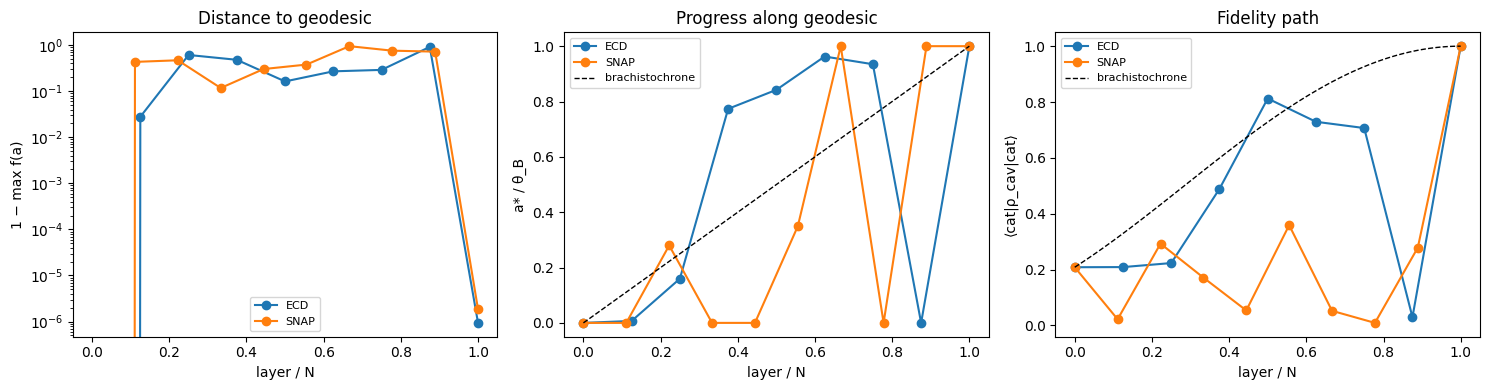

In [5]:
theta_b = jnp.arccos(abs(complex((jnp.transpose(vac) @ cat).squeeze())))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, r in results.items():
    s = jnp.linspace(0, 1, len(r.trajectory))
    axes[0].plot(s, r.geodesic["deviation"], "o-", label=name)
    axes[1].plot(s, r.geodesic["progress"], "o-", label=name)
    axes[2].plot(s, r.trajectory, "o-", label=name)

s_ref = jnp.linspace(0, 1, 100)
axes[1].plot(s_ref, s_ref, "k--", lw=1, label="brachistochrone")
axes[2].plot(s_ref, jnp.cos((1 - s_ref) * theta_b) ** 2, "k--", lw=1, label="brachistochrone")

axes[0].set(xlabel="layer / N", ylabel="1 − max f(a)", title="Distance to geodesic", yscale="log")
axes[1].set(xlabel="layer / N", ylabel="a* / θ_B", title="Progress along geodesic")
axes[2].set(xlabel="layer / N", ylabel="⟨cat|ρ_cav|cat⟩", title="Fidelity path")
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [6]:
def path_efficiency(res, psi_init):
    h = sequence_history(res, psi_init)[:, 0]        # first state pair; states after every gate
    h = h.reshape(h.shape[0], -1)                    # flatten qubit blocks -> joint kets
    h = h / jnp.linalg.norm(h, axis=-1, keepdims=True)
    steps = jnp.arccos(jnp.clip(jnp.abs(jnp.sum(h[:-1].conj() * h[1:], -1)), 0, 1))
    theta_b = jnp.arccos(jnp.clip(abs(jnp.vdot(h[0], h[-1])), 0, 1))
    return theta_b / steps.sum(), steps

for name, r in results.items():
    eta, steps = path_efficiency(r, vac)
    print(f"{name:<12} η = {eta:.3f}   L = {steps.sum():.3f}")

ECD          η = 0.091   L = 12.094
SNAP         η = 0.070   L = 15.607


Things to try next:
- Set `geodesic_weight=0` to see how far an unconstrained solution wanders.
- Sweep the weight, warm-starting each run from the previous one with `params0=prev.flat_params`.
- Switch to `mode="schedule"` to require constant Bures speed.